# 02 — Business Case: From Uplift to Profit

A Qini score doesn't get budget approved — a **profit curve** does. Given a value
per incremental conversion and a cost per treatment, how many users should we
treat, and what does targeting by uplift earn versus treating everyone or
targeting at random?

> **Data note.** Runs on the committed **synthetic** Criteo-like sample so it executes in seconds and redistributes no proprietary data. For real results use the full dataset (`scripts/download_data.py`, then `--use-raw`).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from uplift import config, data
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
df = data.load_sample()
print(f"{len(df):,} rows x {df.shape[1]} columns")

50,000 rows x 16 columns


## Train a model and score the held-out users

We reuse the package pipeline, then take the best model's uplift predictions on the test split.

In [2]:
from uplift.config import ExperimentConfig
from uplift import pipeline, business, evaluation
cfg = ExperimentConfig(outcome="visit", base_learner="lgbm", random_state=42)
result = pipeline.run_experiment(df, cfg)
best = result.metrics.index[0]
u = result.predictions[best]
X_tr, X_te, y_tr, y_te, t_tr, t_te = data.train_test_split_uplift(df, cfg)
print(f"Best model: {best}  (Qini={result.metrics.loc[best,'qini']:.3f})")
result.metrics[['qini','auuc','uplift@10%']]

Best model: S-learner  (Qini=0.101)


,qini,auuc,uplift@10%
model,,,
S-learner,0.1014,0.1044,0.1025
Class transformation,0.0830,0.0859,0.0701
X-learner,0.0677,0.0705,0.0403
T-learner,0.0630,0.0654,0.0371


## Profit assumptions

Illustrative economics — a treatment (impression/offer) costs a little, a conversion is worth a lot. Edit these to your own unit economics.

In [3]:
VALUE_PER_CONVERSION = 50.0   # $ per incremental visit/conversion
COST_PER_TREATMENT   = 1.0    # $ per user treated
curve = business.profit_curve(y_te, t_te, u, VALUE_PER_CONVERSION, COST_PER_TREATMENT)
decision = business.optimal_targeting(y_te, t_te, u, VALUE_PER_CONVERSION, COST_PER_TREATMENT)
pd.Series(decision.as_dict())

best_fraction               0.2329
best_profit              6957.4290
profit_treat_all        -8080.8013
profit_random_at_best   -1881.7493
gain_vs_random           8839.1782
gain_vs_treat_all       15038.2302
dtype: float64

## The profit curve

Profit rises as we treat high-uplift users, peaks at the optimal depth, then falls as we start paying to treat low- and negative-uplift users (sure things, lost causes, sleeping dogs).

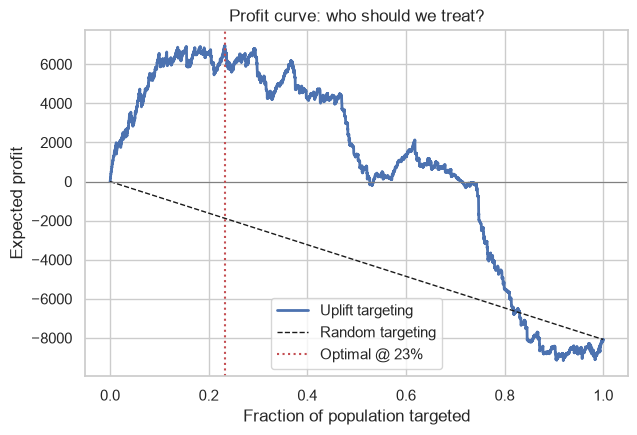

In [4]:
business.plot_profit_curve(curve, decision); plt.show()

## Uplift targeting vs. the baselines

In [5]:
summary = pd.DataFrame({
    "strategy": ["Uplift (optimal depth)", "Treat everyone", "Random @ optimal depth"],
    "profit":   [decision.best_profit, decision.profit_treat_all, decision.profit_random_at_best],
})
summary["vs_treat_all_%"] = 100*(summary["profit"]/decision.profit_treat_all - 1)
summary

,strategy,profit,vs_treat_all_%
0,Uplift (optimal depth),6957.4290,-186.0983
1,Treat everyone,-8080.8013,0.0000
2,Random @ optimal depth,-1881.7493,-76.7133


## Takeaways

* The profit-maximizing policy treats only the top fraction the model flags —
  **not everyone** — and leaves money on the table if you target at random.
* This is decision-ready: plug in real unit economics and the optimal targeting
  depth and expected profit fall straight out.
* The incremental-conversion estimates come from the randomized arms, so the
  profit projection is **causal**, not a correlational forecast.

Implementation: `src/uplift/business.py` (unit-tested in `tests/test_business.py`).